In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install opencv-python

In [ ]:
import cv2
import os
import numpy as np
from google.colab.patches import cv2_imshow

path = '/content/drive/MyDrive/KAU_cropped'
save_path = '/content/drive/MyDrive/HYKAU_aug'

# Angles for the rotation
# angles = [45, 135, 225]

for label in os.listdir(path):
  # Original labels path
  label_path = os.path.join(path, label)
  # Saved labels path
  saved_label_path = os.path.join(save_path, label)
  # Create directory if not exists
  os.makedirs(saved_label_path, exist_ok=True)

  for image_file in os.listdir(label_path):
      # Original image path
      image_path = os.path.join(label_path, image_file)
      # Saved image path
      saved_image_path = os.path.join(saved_label_path, image_file)

      # Read image in grayscale
      image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

      # Resize the image
      resized_image = cv2.resize(image, (208, 208))

      # Define CLAHE
      clahe = cv2.createCLAHE(clipLimit=5)

      # Apply CLAHE to the resized image
      clahe_image = clahe.apply(resized_image)
      final_image = cv2.add(clahe_image, 30)

      # Save the original CLAHE-processed image
      cv2.imwrite(saved_image_path, final_image)

      if label in ['b3', 'b4', 'b5']:
        #To flip the image vertically
        vflipped_image = cv2.flip(final_image, 1)
        cv2.imwrite(os.path.join(saved_label_path, image_file.replace('.jpg', f'_vflip.jpg')), vflipped_image)

        #To flip the image horizontally
        hflipped_image = cv2.flip(final_image, 0)
        cv2.imwrite(os.path.join(saved_label_path, image_file.replace('.jpg', f'_hflip.jpg')), hflipped_image)

In [ ]:
pip install shap

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
import shap

In [ ]:
def HYNet():
    inp = layers.Input((208, 208, 3))
    x = layers.Conv2D(16, 5, 1, padding='valid', activation='relu')(inp)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Conv2D(16, 5, 1, padding='valid', activation='relu')(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Conv2D(14, 3, 1, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Flatten()(x)
    #i dont believe it should have activation relu as the table given in the paper does not have an activation function
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dense(4, activation='softmax')(x)

    houbyyassin = Model(inputs=inp, outputs=x)
    return houbyyassin

In [ ]:
model = HYNet()
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 208, 208, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 204, 204, 16)        │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 102, 102, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 98, 98, 16)          │           6,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 49, 49, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 49, 49, 14)          │           2,030 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 24, 24, 14)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 12, 12, 14)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 2016)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 512)                 │       1,032,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,207,106 (4.60 MB)

 Trainable params: 1,207,106 (4.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss=CategoricalCrossentropy(),
              optimizer=Adam(learning_rate=0.0001),
              metrics=['accuracy', 'precision', 'recall', 'AUC'])

In [ ]:
es = EarlyStopping(patience=5, monitor='loss')

In [ ]:
#to see image with normalizer applied in opencv just inverse it.
def normalizer(img_array):
    img_array = img_array / 255.0  # Normalize to [0, 1] range
    return img_array

In [ ]:
# Load and preprocess images - with help of ChatGPT
def load_and_preprocess_images(path):
    images = []
    labels = []
    label_map = {label: i for i, label in enumerate(os.listdir(path))}
    for label in os.listdir(path):
        for img_file in os.listdir(os.path.join(path, label)):
            img_path = os.path.join(path, label, img_file)
            img = image.load_img(img_path)
            img_array = image.img_to_array(img)
            img_array = normalizer(img_array)
            images.append(img_array)
            labels.append(label_map[label])
    images = np.array(images)
    labels = tf.keras.utils.to_categorical(np.array(labels), num_classes=len(label_map))
    return images, labels

In [ ]:
X, y = load_and_preprocess_images('/content/drive/MyDrive/HYKAU_aug')

# splitting the dataset
X_train, X_temp, y_train, y_temp = train_test_split(X, y, stratify=y, test_size=0.2, random_state=1)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, stratify=y_temp, test_size=0.5, random_state=1)

In [ ]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
import cv2

print("Original class distribution:", Counter(np.argmax(y_train, axis=1)))

def cv_scaled(images, labels, scales = []):
  aug_images = []
  aug_labels = []

  for image, label in zip(images, labels):
    aug_images.append(image)
    aug_labels.append(label)

    if np.argmax(label) in [0, 1, 2]:
      for scale in scales:
        # Scale image using resize function
        scaled_image = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        # Back to original size
        scaled_image = cv2.resize(scaled_image, (208, 208))

        aug_images.append(scaled_image)
        aug_labels.append(label)

  return np.array(aug_images), np.array(aug_labels)

X_train_scaled, y_train_scaled = cv_scaled(X_train, y_train, scales = [0.1, 0.3])

print("After rotation augmentation:")
print("Augmented dataset size:", len(X_train_scaled))

# Flatten X_train if it's an array of images
X_train_sca_flat = X_train_scaled.reshape(X_train_scaled.shape[0], -1)

# Convert one-hot encoded labels to categorical labels
y_train_categorical = np.argmax(y_train_scaled, axis=1)

print("Class distribution:", Counter(y_train_categorical))

#oversampling
oversample = RandomOverSampler(sampling_strategy='auto', random_state=1)
X_train_oversam, y_train_oversam = oversample.fit_resample(X_train_sca_flat, y_train_categorical)

# Reshape X_train_over back to its original dimensions
X_train_oversam = X_train_oversam.reshape(-1, X_train.shape[1], X_train.shape[2], X_train.shape[3])

# Convert categorical labels back to one-hot encoding
y_train_oversam = tf.keras.utils.to_categorical(y_train_oversam, num_classes=y_train.shape[1])

print("Oversampled class distribution:", Counter(np.argmax(y_train_oversam, axis=1)))

Original class distribution: Counter({3: 1706, 2: 950, 0: 341, 1: 58})
After rotation augmentation:
Augmented dataset size: 5753
Class distribution: Counter({2: 2850, 3: 1706, 0: 1023, 1: 174})
Oversampled class distribution: Counter({3: 2850, 2: 2850, 0: 2850, 1: 2850})


In [ ]:
print(len(X_test))
print(len(y_test))

382
382


In [ ]:
history = model.fit(X_train_oversam, y_train_oversam,
                    epochs=30,
                    validation_data=(X_val, y_val),
                    callbacks=[es])

Epoch 1/30
357/357 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - AUC: 0.7354 - accuracy: 0.4575 - loss: 1.1599 - precision: 0.6619 - recall: 0.1689 - val_AUC: 0.8439 - val_accuracy: 0.5969 - val_loss: 0.9189 - val_precision: 0.7130 - val_recall: 0.4031
Epoch 2/30
357/357 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - AUC: 0.9308 - accuracy: 0.7251 - loss: 0.6228 - precision: 0.7762 - recall: 0.6503 - val_AUC: 0.9110 - val_accuracy: 0.6937 - val_loss: 0.7049 - val_precision: 0.7378 - val_recall: 0.6335
Epoch 3/30
357/357 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - AUC: 0.9528 - accuracy: 0.7688 - loss: 0.5005 - precision: 0.7981 - recall: 0.7257 - val_AUC: 0.8952 - val_accuracy: 0.6597 - val_loss: 0.7636 - val_precision: 0.7181 - val_recall: 0.5602
Epoch 4/30
357/357 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - AUC: 0.9664 - accuracy: 0.8100 - loss: 0.4270 - precision: 0.8327 - recall: 0.7797 - val_AUC: 0.9276 - val_accuracy: 0.7356 - val_loss: 0.6349 - val_precision: 0.8000 - val_recall: 0.6702
Epoch 5/30
357/357 ━━━━━━━━

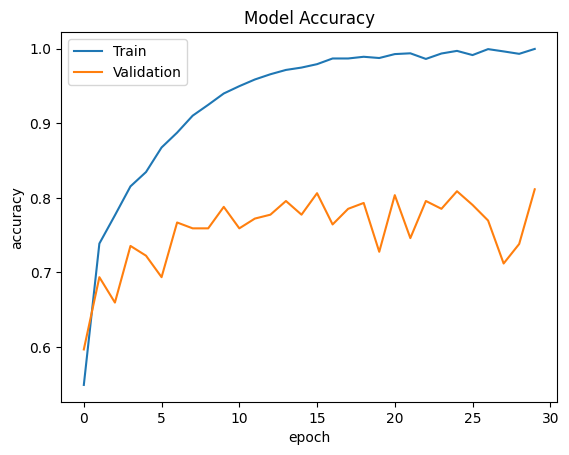

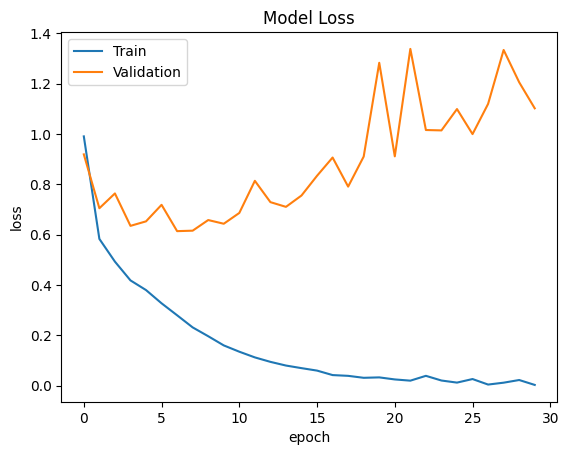

In [ ]:
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
# test_loss, test_accuracy =
results = model.evaluate(X_test, y_test)

test_loss = results[0]
test_accuracy = results[1]
test_precision = results[2]
test_recall = results[3]
test_auc = results[4]

print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")
print(f"Test Precision: {test_precision}")
print(f"Test Recall: {test_recall}")
print(f"Test AUC: {test_auc}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - AUC: 0.9435 - accuracy: 0.8058 - loss: 0.9799 - precision: 0.8177 - recall: 0.8058
Test Loss: 1.1075305938720703
Test Accuracy: 0.8141361474990845
Test Precision: 0.8205804824829102
Test Recall: 0.8141361474990845
Test AUC: 0.936650812625885


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

label_mapping = {0: 4, 1: 5, 2: 3, 3: 1}
ordered = [1, 3, 4, 5]
mapped_labels = [label_mapping[i] for i in range(len(label_mapping))]

#to get predictions made on the test set
y_pred = model.predict(X_test)

#converting the prediction labels to class labels for the matrix
y_pred_classes = np.argmax(y_pred, axis=1)
#converting the true test labels to class labels for the matrix
y_test_classes = np.argmax(y_test, axis=1)

#computing the confusion matrix
conf_matrix = confusion_matrix(y_test_classes, y_pred_classes)

# Map the labels
remapped_true = np.vectorize(label_mapping.get)(y_test_classes)
remapped_pred = np.vectorize(label_mapping.get)(y_pred_classes)
conf_matrix_remapped = confusion_matrix(remapped_true, remapped_pred, labels=ordered)

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step


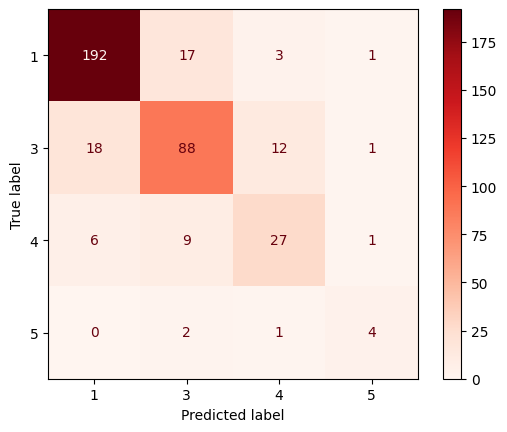

In [ ]:
# disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=[1, 3, 4, 5])
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_remapped, display_labels=ordered)
disp.plot(cmap=plt.cm.Reds)
plt.show()

In [ ]:
def f(x):
    tmp = x.copy()
    return model.predict(tmp)

masker_blur = shap.maskers.Image("blur(8,8)", X_test[0].shape)
explainer = shap.Explainer(f, masker_blur, output_names=list(range(y.shape[1])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━

  0%|          | 0/4998 [00:00<?, ?it/s]

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━

PartitionExplainer explainer: 2it [00:16, 16.99s/it]               

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Actual class: [5]
Predicted class: [5]


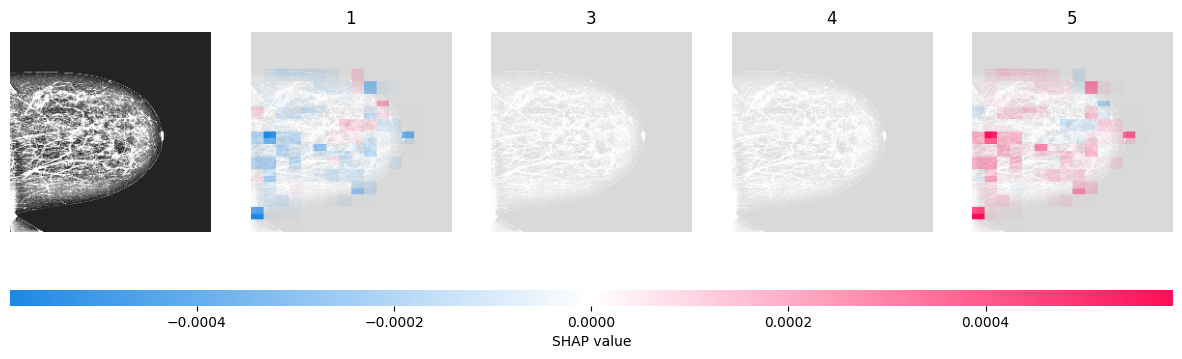

In [ ]:
#random index number for images in array to compute the SHAP values for
ind = [100]

# computing SHAP values for a subset of test data
shap_values_ = explainer(X_test[ind], max_evals=5000, batch_size=50)

actual_index = np.argmax(y_test[ind], axis=-1)
predicted_index = np.argmax(model.predict(X_test[ind]), axis=-1)  #model predictions

# change from 0,1, 2, 3 labels to the original 1, 3, 4, 5 labels
label_mapping = {0: 1, 1: 3, 2: 4, 3: 5}

# Map the actual and predicted class indices to the new labels
actual_class = [label_mapping[i] for i in actual_index]
predicted_class = [label_mapping[i] for i in predicted_index]

print(f"Actual class: {actual_class}")
print(f"Predicted class: {predicted_class}")

# Get the labels in the right order based on y.shape[1]
mapped_labels = [label_mapping[i] for i in range(y.shape[1])]

# Use the mapped labels in the SHAP plot
shap.image_plot(shap_values_, labels=mapped_labels)

# plotting SHAP values
# shap.image_plot(shap_values_, labels=list(range(y.shape[1])))

Actual class: [4]
Predicted class: [4]


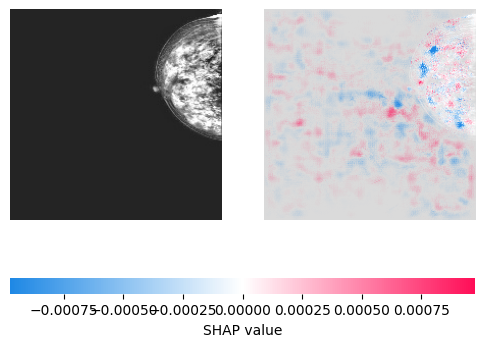

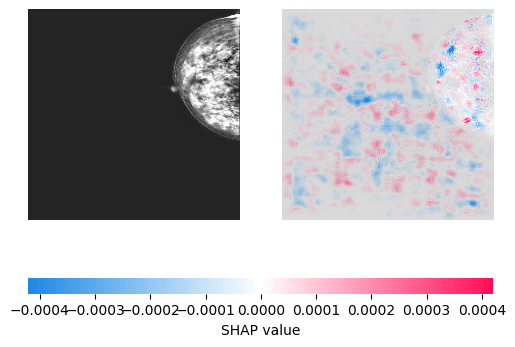

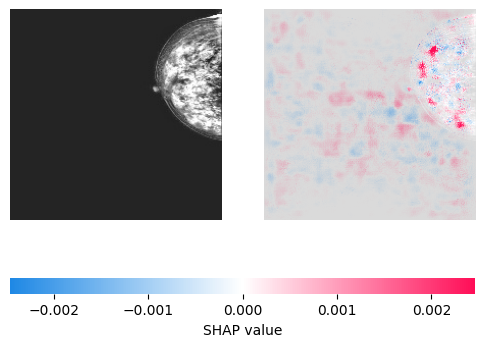

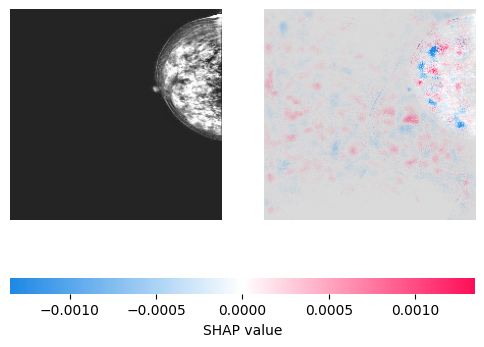

In [ ]:
# background = X_train[np.random.choice(X_train.shape[0], 100, replace=False)]
np.random.seed(1)
background = X_train_oversam[np.random.choice(X_train_oversam.shape[0], 100, replace=False)]
e = shap.DeepExplainer(model, background)
ind=[20]
shap_values = e.shap_values(X_test[ind])
# shap.image_plot(shap_values[..., 3], X_test[ind])

#line to check that shap_values recognizes the 4 classes
# print(np.array(shap_values).shape) #it does

print(f"Actual class: {actual_class}")
print(f"Predicted class: {predicted_class}")

for i in range(4):  # Iterate over the last dimension (classes)
    shap.image_plot([shap_values[..., i]], X_test[ind])

#figure out how to plot on the same axis